# Exploration

Explorar datos 

## Packages

In [1]:
from datetime import datetime, timedelta
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
from mpl_toolkits.mplot3d import Axes3D


## días elegidos

In [2]:
d1 = pd.to_datetime("1980-02-04")
d2 = pd.to_datetime("2025-11-15")

dias = (d2 - d1).days
dias

16721

In [3]:
step = dias / (2090 - 1)
step

8.00430828147439

## Parameters

In [4]:
# ============================================================
# 1. PARÁMETROS DEL ANÁLISIS
# ============================================================
n=16752
new_n = 8164 # nuevo número de días
fecha_actual = "2025-12-01"
# Parámetros de FAI
window_minutes=30
fai_temp_range = (8, 35)
fai_em_jump = 0.015
fai_em_threshold_d=fai_em_jump
date_column = "date"
duration = True
FAI_duration = 4
exclude_last_minutes = 20 # minutos al final del día para excluir FAIs
filter_flare_coincidence = True
method = "filteredend_nooverlap" # "all", "true", "filtered", "filteredend" o "filteredend_nooverlap"
flares="ABCMX" # "valid", "no_A", "no_A_B", 
                                  # "no_A_B_nonoverlap" o "no_A_B_nonoverlap_wstart"
                                  # "M_X_nonoverlap_wstart"
nooverlap = True
min_gap_minutes_overlap = 20 #FILTRO EXTRA: remover FAI que ocurren tras un flare en [end, end + min_gap_minutes_overlap] 

# Formato de threshold para nombres de carpetas
threshold_str = f"{fai_em_jump}"   # "0.005" # convertir a string sin notación científica
fai_em_threshold_d = threshold_str.replace(".", "d") # reemplazar el punto por 'd'


## Carpeta

In [5]:
analysis_dir = os.path.join(f"Data_for_{n}_days/Analysis_FAI")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_dir ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_dir }")
else:
    os.makedirs(analysis_dir , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_dir}")

# Crear subcarpeta para guardar resultados de análisis
analysis_esp = os.path.join(analysis_dir, f"Analysis_FAI_{flares}_T{fai_temp_range[0]}-{fai_temp_range[1]}_dEM{fai_em_threshold_d}_dur{FAI_duration}min")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_esp ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_esp }")
else:
    os.makedirs(analysis_esp , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_esp}")

⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI
⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min


## Valid Data 

In [6]:
input_dir = f"Data_for_{n}_days"

# Path of cleaned data in csv
csv_path_full_valid = f"{input_dir}/df_full_{new_n}_valid.csv"
# Path of valid flares: 
csv_path_all_flares = f"{input_dir}/all_df_flare_data_{n}.csv"
csv_path_flares_valid = f"{input_dir}/df_flares_{new_n}_valid.csv"
csv_path_flares = f"{input_dir}/df_flares_{new_n}_{flares}.csv"

#csv_path_flares = f"{input_dir}/all_df_flares_{n}_cleaned.csv"
# Path of df_full
csv_path_full = f"{input_dir}/all_df_full_{n}.csv"

# Verificar existencia de archivos y avisar
if not os.path.exists(csv_path_full_valid):
    print(f"⚠️ No se encontró el archivo GOES: {csv_path_full_valid}")
else:
    print(f"✅ Archivo GOES encontrado: {csv_path_full_valid}")

if not os.path.exists(csv_path_all_flares):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_all_flares}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_all_flares}")
          
if not os.path.exists(csv_path_flares_valid):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_flares_valid}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_flares_valid}")

if not os.path.exists(csv_path_flares):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_flares}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_flares}")

if not os.path.exists(csv_path_full):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_full}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_full}")

df_full_valid = pd.read_csv(csv_path_full_valid)
df_flares_all = pd.read_csv(csv_path_all_flares)
df_flares_valid = pd.read_csv(csv_path_flares)
df_flares = pd.read_csv(csv_path_flares)
df_full = pd.read_csv(csv_path_full)

✅ Archivo GOES encontrado: Data_for_16752_days/df_full_8164_valid.csv
✅ Archivo de flares encontrado: Data_for_16752_days/all_df_flare_data_16752.csv
✅ Archivo de flares encontrado: Data_for_16752_days/df_flares_8164_valid.csv
✅ Archivo de flares encontrado: Data_for_16752_days/df_flares_8164_ABCMX.csv
✅ Archivo de flares encontrado: Data_for_16752_days/all_df_full_16752.csv


## Data_method

In [7]:
# Path of anticipation_time
csv_path_anticipation_time = f"{analysis_esp}/df_anticipation_time_{method}_(W_{window_minutes})_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of fai_all
csv_path_fai_all = f"{analysis_esp}/df_fai_all_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of fai_selected
csv_path_fai_selected = f"{analysis_esp}/df_fai_{method}_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of df_fai_assoc
csv_path_fai_assoc = f"{analysis_esp}/df_fai_assoc_{method}_(W_{window_minutes})_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"

if not os.path.exists(csv_path_anticipation_time):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_anticipation_time}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_anticipation_time}")
if not os.path.exists(csv_path_fai_all):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_all}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_all}")
if not os.path.exists(csv_path_fai_selected):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_selected}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_selected}")
if not os.path.exists(csv_path_fai_assoc):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_assoc}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_assoc}")


df_anticipation_time = pd.read_csv(csv_path_anticipation_time)
df_fai_all = pd.read_csv(csv_path_fai_all)
df_fai_selected = pd.read_csv(csv_path_fai_selected)
df_fai_assoc = pd.read_csv(csv_path_fai_assoc)



✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_anticipation_time_filteredend_nooverlap_(W_30)_T8-35_EM0d015_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_fai_all_T8-35_EM0d015_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_fai_filteredend_nooverlap_T8-35_EM0d015_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_fai_assoc_filteredend_nooverlap_(W_30)_T8-35_EM0d015_dur4min.csv


## dfs columns to datatime

In [8]:
df_full_valid["date"] = pd.to_datetime(df_full_valid["date"])
df_flares_valid["StartTime"] = pd.to_datetime(df_flares_valid["StartTime"])
df_flares_valid["PeakTime"]  = pd.to_datetime(df_flares_valid["PeakTime"])
df_flares_valid["EndTime"]   = pd.to_datetime(df_flares_valid["EndTime"])
df_anticipation_time["StartTime"] = pd.to_datetime(df_anticipation_time["StartTime"])
df_anticipation_time["PeakTime"]  = pd.to_datetime(df_anticipation_time["PeakTime"])
df_anticipation_time["EndTime"]   = pd.to_datetime(df_anticipation_time["EndTime"])
df_fai_selected["date"] = pd.to_datetime(df_fai_selected["date"])

## info df

In [9]:
df_full_valid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1603921 entries, 0 to 1603920
Data columns (total 15 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   date          1603921 non-null  datetime64[ns]
 1   observatory   1603921 non-null  object        
 2   xrsa          1603921 non-null  float64       
 3   xrsb          1603921 non-null  float64       
 4   xrsa_corr     1603921 non-null  float64       
 5   xrsb_corr     1603921 non-null  float64       
 6   T_cor         1603921 non-null  float64       
 7   EM_cor        1603921 non-null  float64       
 8   T_phot        1603921 non-null  float64       
 9   EM_phot       1603921 non-null  float64       
 10  EM_cor_norm   1603921 non-null  float64       
 11  EM_phot_norm  1603921 non-null  float64       
 12  month         1603921 non-null  int64         
 13  day           1603921 non-null  object        
 14  GOES_missing  1603921 non-null  bool          
dty

In [10]:
df_full_valid.head()

,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing
0,1980-04-23 00:12:00,GOES-2,7.942158e-09,8.763737e-07,1.587264e-09,4.015794e-08,7.060729,3.690231e+46,6.135368,1.300606e+47,0.003690,0.013006,4,1980-04-23,False
1,1980-04-23 00:13:00,GOES-2,7.927400e-09,8.802400e-07,1.688900e-09,4.180504e-08,7.130107,3.764167e+46,6.197556,1.320373e+47,0.003764,0.013204,4,1980-04-23,False
2,1980-04-23 00:14:00,GOES-2,7.772947e-09,8.835316e-07,1.474247e-09,4.361658e-08,6.588273,4.663026e+46,5.715241,1.696103e+47,0.004663,0.016961,4,1980-04-23,False
3,1980-04-23 00:15:00,GOES-2,8.490200e-09,8.980400e-07,2.389410e-09,5.425579e-08,7.412348,4.516885e+46,6.451488,1.554051e+47,0.004517,0.015541,4,1980-04-23,False
4,1980-04-23 00:16:00,GOES-2,9.656500e-09,9.167300e-07,2.472850e-09,5.775001e-08,7.318921,4.930460e+46,6.367286,1.707211e+47,0.004930,0.017072,4,1980-04-23,False


In [11]:
df_flares_valid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48344 entries, 0 to 48343
Data columns (total 26 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Flare_ID     48344 non-null  object        
 1   StartTime    48344 non-null  datetime64[ns]
 2   PeakTime     48344 non-null  datetime64[ns]
 3   EndTime      48344 non-null  datetime64[ns]
 4   StartPeak    48344 non-null  float64       
 5   StartEnd     48344 non-null  float64       
 6   PeakEnd      48344 non-null  float64       
 7   Class        48344 non-null  object        
 8   ClassLetter  48344 non-null  object        
 9   ClassNumber  48344 non-null  float64       
 10  ClassGroup   48344 non-null  object        
 11  NOAA_Class   0 non-null      float64       
 12  PeakFlux     37 non-null     float64       
 13  Observatory  48344 non-null  object        
 14  Instrument   48344 non-null  object        
 15  NumSpots     0 non-null      float64       
 16  NOAA

In [12]:
df_anticipation_time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48344 entries, 0 to 48343
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Flare_ID                    48344 non-null  object        
 1   StartTime                   48344 non-null  datetime64[ns]
 2   PeakTime                    48344 non-null  datetime64[ns]
 3   EndTime                     48344 non-null  datetime64[ns]
 4   StartPeak                   48344 non-null  float64       
 5   StartEnd                    48344 non-null  float64       
 6   PeakEnd                     48344 non-null  float64       
 7   Class                       48344 non-null  object        
 8   ClassLetter                 48344 non-null  object        
 9   ClassNumber                 48344 non-null  float64       
 10  ClassGroup                  48344 non-null  object        
 11  NOAA_Class                  0 non-null      float64   

In [13]:
df_fai_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12431 entries, 0 to 12430
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   date                 12431 non-null  datetime64[ns]
 1   observatory          12431 non-null  object        
 2   xrsa                 12431 non-null  float64       
 3   xrsb                 12431 non-null  float64       
 4   xrsa_corr            12431 non-null  float64       
 5   xrsb_corr            12431 non-null  float64       
 6   T_cor                12431 non-null  float64       
 7   EM_cor               12431 non-null  float64       
 8   T_phot               12431 non-null  float64       
 9   EM_phot              12431 non-null  float64       
 10  EM_cor_norm          12431 non-null  float64       
 11  EM_phot_norm         12431 non-null  float64       
 12  month                12431 non-null  int64         
 13  day                  12431 non-

In [14]:
df_fai_assoc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12431 entries, 0 to 12430
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 12431 non-null  object 
 1   observatory          12431 non-null  object 
 2   xrsa                 12431 non-null  float64
 3   xrsb                 12431 non-null  float64
 4   xrsa_corr            12431 non-null  float64
 5   xrsb_corr            12431 non-null  float64
 6   T_cor                12431 non-null  float64
 7   EM_cor               12431 non-null  float64
 8   T_phot               12431 non-null  float64
 9   EM_phot              12431 non-null  float64
 10  EM_cor_norm          12431 non-null  float64
 11  EM_phot_norm         12431 non-null  float64
 12  month                12431 non-null  int64  
 13  day                  12431 non-null  object 
 14  GOES_missing         12431 non-null  bool   
 15  EM_diff              12431 non-null 

## df_anticipation_time - todos los flares

In [15]:
df_anticipation_time.info() # todos los flares

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48344 entries, 0 to 48343
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Flare_ID                    48344 non-null  object        
 1   StartTime                   48344 non-null  datetime64[ns]
 2   PeakTime                    48344 non-null  datetime64[ns]
 3   EndTime                     48344 non-null  datetime64[ns]
 4   StartPeak                   48344 non-null  float64       
 5   StartEnd                    48344 non-null  float64       
 6   PeakEnd                     48344 non-null  float64       
 7   Class                       48344 non-null  object        
 8   ClassLetter                 48344 non-null  object        
 9   ClassNumber                 48344 non-null  float64       
 10  ClassGroup                  48344 non-null  object        
 11  NOAA_Class                  0 non-null      float64   

In [16]:
print(df_anticipation_time.iloc[:3].to_string())


            Flare_ID           StartTime            PeakTime             EndTime  StartPeak  StartEnd  PeakEnd Class ClassLetter  ClassNumber ClassGroup  NOAA_Class  PeakFlux Observatory Instrument  NumSpots  NOAA_AR  Zurich  McIntosh  MtWilson     HPC_X     HPC_Y  HGS_Long  HGS_Lat EventType  EventType2  FAIalerts_W  FAIalerts_WStart  FAIalerts_WPeak  FAIalerts_StartPeak  FAIalerts_PeakEnd  FAIalerts_startEnd  AnticipationStart  AnticipationPeak  Peak_to_lastFAI  Time_since_prev_flare_end  Time_since_prev_flare_peak  RelAnticipation_Peak  RelAnticipation_Start
0  198004240553_C2.0 1980-04-24 05:50:00 1980-04-24 05:53:00 1980-04-24 06:30:00        3.0      40.0     37.0  C2.0           C          2.0     C1-4.9         NaN       NaN        GOES       GOES       NaN   2396.0     NaN       NaN       NaN -65.09340 -137.1822      -4.0    -13.0        FL           9            0                 0                0                    0                  0                   0                NaN

In [17]:
df_anticipation_time.head()

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,...,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
0,198004240553_C2.0,1980-04-24 05:50:00,1980-04-24 05:53:00,1980-04-24 06:30:00,3.0,40.0,37.0,C2.0,C,2.0,...,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,198004240932_C1.0,1980-04-24 09:29:00,1980-04-24 09:32:00,1980-04-24 09:40:00,3.0,11.0,8.0,C1.0,C,1.0,...,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,198004241815_C4.0,1980-04-24 17:59:00,1980-04-24 18:15:00,1980-04-24 19:10:00,16.0,71.0,55.0,C4.0,C,4.0,...,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,198004251747_C2.0,1980-04-25 17:29:00,1980-04-25 17:47:00,1980-04-25 18:16:00,18.0,47.0,29.0,C2.0,C,2.0,...,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,198004251943_C2.0,1980-04-25 19:35:00,1980-04-25 19:43:00,1980-04-25 20:22:00,8.0,47.0,39.0,C2.0,C,2.0,...,0,0,0,NaN,NaN,NaN,87.0,116.0,NaN,NaN


### verificar que no esté tomando FAI entre el peak y end

In [18]:
df_anticipation_time.sort_values(by="FAIalerts_PeakEnd", ascending=False)[:2]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,...,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
0,198004240553_C2.0,1980-04-24 05:50:00,1980-04-24 05:53:00,1980-04-24 06:30:00,3.0,40.0,37.0,C2.0,C,2.0,...,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,198004240932_C1.0,1980-04-24 09:29:00,1980-04-24 09:32:00,1980-04-24 09:40:00,3.0,11.0,8.0,C1.0,C,1.0,...,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## mostrar # de alertas antes del start de mayor a menor

In [92]:
# Configurar pandas para mostrar todas las columnas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

df_anticipation_time.sort_values(by="FAIalerts_WStart", ascending=False)[40:50]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
42893,202305181213_M1.9,2023-05-18 12:00:00,2023-05-18 12:13:00,2023-05-18 12:22:00,13.000000,22.0,9.000000,M1.9,M,1.9,M1-4.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.000000,38.698687,0.00000,0.00000,FL,9,3,3,3,0,0,0,18.0,31.000000,29.000000,54.000000,68.000000,2.384615,1.384615
3905,198705191810_C9.6,1987-05-19 18:08:00,1987-05-19 18:10:00,1987-05-19 18:37:00,2.000000,29.0,27.000000,C9.6,C,9.6,C5-9.9,NaN,NaN,GOES,GOES,NaN,4811.0,NaN,NaN,NaN,-348.124800,503.341200,-25.00000,30.00000,FL,9,3,3,3,0,0,0,3.0,5.000000,3.000000,NaN,NaN,2.500000,1.500000
42601,202304141659_C5.3,2023-04-14 16:44:00,2023-04-14 16:59:00,2023-04-14 17:08:00,15.000000,24.0,9.000000,C5.3,C,5.3,C5-9.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.000000,95.015712,0.00000,0.00000,FL,9,3,3,3,0,0,0,28.0,43.000000,41.000000,66.000000,70.000000,2.866667,1.866667
46884,202502022336_M3.2,2025-02-02 23:33:00,2025-02-02 23:36:00,2025-02-03 00:13:00,3.000000,40.0,37.000000,M3.2,M,3.2,M1-4.9,NaN,NaN,SDO,AIA,NaN,3981.0,NaN,NaN,NaN,-441.839406,177.733302,-27.00000,5.00000,FL,9,3,3,3,0,0,0,16.0,19.000000,17.000000,45.000000,49.000000,6.333333,5.333333
1427,198212250750_X2.2,1982-12-25 07:43:00,1982-12-25 07:50:00,1982-12-25 08:43:00,7.000000,60.0,53.000000,X2.2,X,2.2,X1-4.9,NaN,NaN,GOES,GOES,NaN,4033.0,NaN,NaN,NaN,-489.226200,-205.474800,-31.00000,-14.00000,FL,9,10,3,10,7,0,7,3.0,10.000000,1.000000,69.000000,82.000000,1.428571,0.428571
221,198011060348_X9.0,1980-11-06 03:40:00,1980-11-06 03:48:00,1980-11-06 05:28:00,8.000000,108.0,100.000000,X9.0,X,9.0,X5-+,NaN,NaN,GOES,GOES,NaN,2779.0,NaN,NaN,NaN,-910.842000,-218.241600,-74.00000,-12.00000,FL,9,6,3,6,3,0,3,8.0,16.000000,5.000000,120.000000,156.000000,2.000000,1.000000
34925,201410271009_M6.7,2014-10-27 09:59:00,2014-10-27 10:09:00,2014-10-27 10:26:00,10.000000,27.0,17.000000,M6.7,M,6.7,M5-9.9,NaN,NaN,GOES,GOES,NaN,12192.0,NaN,NaN,NaN,0.000000,-81.960000,0.00000,0.00000,FL,9,9,3,9,6,0,6,7.0,17.000000,5.000000,NaN,NaN,1.700000,0.700000
20213,200007102109_M5.7,2000-07-10 21:03:18,2000-07-10 21:09:38,2000-07-10 21:39:24,6.333333,36.1,29.766667,M5.7,M,5.7,M5-9.9,NaN,0.0,Yohkoh,HXT,NaN,9070.0,NaN,NaN,NaN,560.900000,252.300000,38.68706,18.56143,FL,9,3,3,3,0,0,0,27.3,33.633333,31.633333,56.633333,64.633333,5.310526,4.310526
19304,199911141623_M2.2,1999-11-14 16:20:00,1999-11-14 16:23:00,1999-11-14 16:26:00,3.000000,6.0,3.000000,M2.2,M,2.2,M1-4.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.000000,-49.814460,0.00000,0.00000,FL,9,3,3,3,0,0,0,16.0,19.000000,17.000000,41.000000,43.000000,6.333333,5.333333
15399,199408170108_M1.5,1994-08-17 01:07:00,1994-08-17 01:08:00,1994-08-17 01:53:00,1.000000,46.0,45.000000,M1.5,M,1.5,M1-4.9,NaN,NaN,GOES,GOES,NaN,7765.0,NaN,NaN,NaN,526.590000,-332.445000,35.00000,-15.00000,FL,9,2,2,2,0,0,0,2.0,3.000000,2.000000,26.000000,37.000000,3.000000,2.000000


## mostrar # de alertas en toda la ventana de menor a mayor

donde FAIalerts_W = 0 -> Flares que no tienen alerta de anticipación

In [87]:
# Configurar pandas para mostrar todas las columnas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

df_anticipation_time.sort_values(by="FAIalerts_W", ascending=False)[28:38]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
34128,201404021405_M6.5,2014-04-02 13:18:00,2014-04-02 14:05:00,2014-04-02 14:28:00,47.0,70.0,23.0,M6.5,M,6.5,M5-9.9,NaN,NaN,GOES,GOES,NaN,12027.0,NaN,NaN,NaN,-745.314000,294.48780,-53.0,14.0,FL,9,12,0,12,12,0,12,NaN,21.0,10.0,97.0,102.0,0.446809,NaN
19252,199911051829_M3.0,1999-11-05 18:04:00,1999-11-05 18:29:00,1999-11-05 19:44:00,25.0,100.0,75.0,M3.0,M,3.0,M1-4.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.000000,-66.58380,0.0,0.0,FL,9,12,0,12,12,0,12,NaN,21.0,10.0,67.0,71.0,0.840000,NaN
33765,201401071830_X1.2,2014-01-07 18:04:00,2014-01-07 18:30:00,2014-01-07 18:58:00,26.0,54.0,28.0,X1.2,X,1.2,X1-4.9,NaN,NaN,SDO,AIA,NaN,0.0,NaN,NaN,NaN,133.372986,-140.85177,8.0,-12.0,FL,9,12,0,12,12,0,12,NaN,20.0,9.0,NaN,NaN,0.769231,NaN
18905,199907190846_M5.8,1999-07-19 08:16:00,1999-07-19 08:46:00,1999-07-19 09:10:00,30.0,54.0,24.0,M5.8,M,5.8,M5-9.9,NaN,NaN,GOES,GOES,NaN,8636.0,NaN,NaN,NaN,-771.060000,253.33140,-59.0,18.0,FL,9,12,0,12,12,0,12,NaN,26.0,7.0,NaN,NaN,0.866667,NaN
32839,201305131605_X2.8,2013-05-13 15:48:00,2013-05-13 16:05:00,2013-05-13 16:16:00,17.0,28.0,11.0,X2.8,X,2.8,X1-4.9,NaN,NaN,GOES,GOES,NaN,11748.0,NaN,NaN,NaN,-928.284000,184.90260,-85.0,11.0,FL,9,12,0,12,12,0,12,NaN,12.0,1.0,55.0,85.0,0.705882,NaN
30136,201108031345_M6.0,2011-08-03 13:17:00,2011-08-03 13:45:00,2011-08-03 14:30:00,28.0,73.0,45.0,M6.0,M,6.0,M5-9.9,NaN,NaN,SDO,AIA,NaN,1261.0,NaN,NaN,NaN,453.634800,194.71920,30.0,17.0,FL,9,11,0,11,11,0,11,NaN,20.0,10.0,NaN,NaN,0.714286,NaN
10003,199104151015_M9.8,1991-04-15 09:23:00,1991-04-15 10:15:00,1991-04-15 10:21:00,52.0,58.0,6.0,M9.8,M,9.8,M5-9.9,NaN,NaN,GOES,GOES,NaN,6593.0,NaN,NaN,NaN,-883.140000,-150.40620,-70.0,-11.0,FL,9,11,0,11,11,0,11,NaN,43.0,11.0,95.0,113.0,0.826923,NaN
26717,200507071629_M4.9,2005-07-07 16:07:00,2005-07-07 16:29:00,2005-07-07 16:40:00,22.0,33.0,11.0,M4.9,M,4.9,M1-4.9,NaN,NaN,GOES,GOES,NaN,10786.0,NaN,NaN,NaN,-48.978360,89.33160,-3.0,9.0,FL,9,11,0,11,11,0,11,NaN,15.0,5.0,55.0,70.0,0.681818,NaN
24279,200310191650_X1.1,2003-10-19 16:29:00,2003-10-19 16:50:00,2003-10-19 17:04:00,21.0,35.0,14.0,X1.1,X,1.1,X1-4.9,NaN,NaN,GOES,GOES,NaN,10484.0,NaN,NaN,NaN,-810.576000,84.77880,-58.0,8.0,FL,9,11,0,11,11,0,11,NaN,15.0,5.0,NaN,NaN,0.714286,NaN
22833,200208161232_M5.2,2002-08-16 11:32:00,2002-08-16 12:32:00,2002-08-16 13:07:00,60.0,95.0,35.0,M5.2,M,5.2,M5-9.9,NaN,NaN,GOES,GOES,NaN,10069.0,NaN,NaN,NaN,0.000000,-111.04080,0.0,0.0,FL,9,11,0,11,11,0,11,NaN,30.0,20.0,NaN,NaN,0.500000,NaN


In [20]:
# Ver distribución de todos los valores
distribucion = df_anticipation_time['FAIalerts_W'].value_counts().sort_index()
print("Distribución de FAIalerts_W:")
print(distribucion)



Distribución de FAIalerts_W:
FAIalerts_W
0     43784
1      1789
2      1327
3       609
4       345
5       177
6       106
7        67
8        44
9        33
10       15
11       15
12       13
13        8
14        5
15        4
16        2
17        1
Name: count, dtype: int64


In [21]:
# O con porcentajes
distribucion_pct = df_anticipation_time['FAIalerts_W'].value_counts(normalize=True).sort_index() * 100
print("\nDistribución en porcentajes:")
print(distribucion_pct)


Distribución en porcentajes:
FAIalerts_W
0     90.567599
1      3.700563
2      2.744911
3      1.259722
4      0.713636
5      0.366126
6      0.219262
7      0.138590
8      0.091014
9      0.068261
10     0.031028
11     0.031028
12     0.026891
13     0.016548
14     0.010343
15     0.008274
16     0.004137
17     0.002069
Name: proportion, dtype: float64


## número de flares por clase

In [22]:
# Ver distribución de todos los valores
distribucion = df_anticipation_time['ClassLetter'].value_counts().sort_index()
print("Distribución de ClassLetter:")
print(distribucion)

Distribución de ClassLetter:
ClassLetter
A      470
B    15412
C    28892
M     3347
X      223
Name: count, dtype: int64


In [23]:
# Ver distribución de todos los valores
distribucion = df_anticipation_time['ClassGroup'].value_counts().sort_index()
print("Distribución de ClassGroup:")
print(distribucion)

Distribución de ClassGroup:
ClassGroup
A1-4.9      150
A5-9.9      320
B1-4.9     8682
B5-9.9     6730
C1-4.9    23938
C5-9.9     4954
M1-4.9     3025
M5-9.9      322
X1-4.9      202
X5-+         21
Name: count, dtype: int64


## Explorar qué pasa en los flares X que no tienen alerta

### Estadística

In [24]:
# Resumen rápido de todas las columnas numéricas
df_anticipation_time.describe()


/Users/nohoraprieto/miniforge3/envs/sunpy/lib/python3.13/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/Users/nohoraprieto/miniforge3/envs/sunpy/lib/python3.13/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,ClassNumber,NOAA_Class,PeakFlux,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
count,48344,48344,48344,48344.000000,48344.000000,48344.000000,48344.000000,0.0,37.0,0.0,48322.000000,0.0,0.0,0.0,48344.000000,48344.000000,48344.000000,48344.000000,48344.0,48344.000000,48344.000000,48344.000000,48344.000000,48344.0,48344.000000,212.000000,4560.000000,4560.000000,30718.000000,29370.000000,4560.000000,212.000000
mean,2004-09-22 22:19:59.615112704,2004-09-22 22:30:10.162626304,2004-09-22 22:42:24.572790912,10.175792,22.415961,12.240169,3.580827,NaN,0.0,NaN,5027.099272,NaN,NaN,NaN,-9.802430,-15.111682,-0.749888,-0.793304,9.0,0.228425,0.008729,0.228425,0.219696,0.0,0.219696,10.001808,6.823023,4.744295,88.210156,95.052917,inf,inf
min,1980-04-24 05:50:00,1980-04-24 05:53:00,1980-04-24 06:30:00,0.000000,0.000000,0.000000,1.000000,NaN,0.0,NaN,0.000000,NaN,NaN,NaN,-974.340000,-967.743240,-93.000000,-86.000000,9.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,1.000000,1.000000,0.066667,20.000000,23.000000,0.012987,0.023810
25%,1992-03-17 20:07:00,1992-03-17 20:30:30,1992-03-17 20:43:30,4.000000,9.000000,4.000000,1.700000,NaN,0.0,NaN,0.000000,NaN,NaN,NaN,0.000000,-114.453750,0.000000,0.000000,9.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,3.000000,2.000000,1.000000,52.000000,61.000000,0.200000,0.595833
50%,2003-08-03 11:19:30,2003-08-03 11:30:00,2003-08-03 11:45:30,6.000000,14.000000,7.000000,2.700000,NaN,0.0,NaN,3878.000000,NaN,NaN,NaN,0.000000,-14.824539,0.000000,0.000000,9.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,8.000000,4.000000,2.000000,82.000000,90.000000,0.363636,1.733333
75%,2015-10-17 04:46:00,2015-10-17 04:50:00,2015-10-17 04:54:30,11.000000,25.000000,14.000000,5.000000,NaN,0.0,NaN,10682.000000,NaN,NaN,NaN,0.000000,97.282050,0.000000,0.000000,9.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,16.000000,8.000000,5.000000,120.000000,127.000000,0.562500,5.333333
max,2025-11-15 23:24:00,2025-11-15 23:29:00,2025-11-15 23:34:00,317.000000,673.000000,633.000000,14.400000,NaN,0.0,NaN,14281.000000,NaN,NaN,NaN,984.400000,967.380000,93.000000,86.000000,9.0,17.000000,8.000000,17.000000,17.000000,0.0,17.000000,30.000000,180.000000,179.000000,180.000000,180.000000,inf,inf
std,NaN,NaN,NaN,13.182524,25.449750,16.415925,2.395082,NaN,0.0,NaN,5145.510739,NaN,NaN,NaN,419.785598,198.078602,33.667791,11.401850,0.0,0.929963,0.158097,0.929963,0.910872,0.0,0.910872,8.324964,10.246858,8.337024,42.298800,40.642935,NaN,NaN


In [25]:
df_anticipation_time['Observatory'].value_counts()

Observatory
GOES                        43760
SDO                          4249
GOES16                        116
SoHO                           92
Yohkoh                         37
GOES      14                   33
STEREO - Behind (BEACON)       26
STEREO - Ahead (BEACON)        12
GOES18                         11
TRACE                           5
STEREO                          2
GOES      15                    1
Name: count, dtype: int64

In [26]:
df_anticipation_time['Instrument'].value_counts()

Instrument
GOES      43760
AIA        4249
SUVI        127
EIT          92
SECCHI       40
HXT          36
SXI          34
TRACE         5
GRS           1
Name: count, dtype: int64

In [27]:
# Filtrar y ordenar
resultadoXsinFAI = df_anticipation_time[
    (df_anticipation_time['FAIalerts_W'] == 0) & 
    (df_anticipation_time['ClassLetter'] == 'X')
].sort_values(by='Class', ascending=False)

# Filtrar y ordenar
resultadoXconFAI = df_anticipation_time[
    (df_anticipation_time['FAIalerts_W'] != 0) & 
    (df_anticipation_time['ClassLetter'] == 'X')
].sort_values(by='Class', ascending=False)

print(f'{len(resultadoXsinFAI)} flares clase X NO tienen alerta \n{len(resultadoXconFAI)} flares clase X SI tienen alerta')
print(f'{len(resultadoXsinFAI) + len(resultadoXconFAI)} Total clase X')

32 flares clase X NO tienen alerta 
191 flares clase X SI tienen alerta
223 Total clase X


In [28]:
# Crear la tabla resumen por ClassLetter
resumen_clases = df_anticipation_time.groupby('ClassLetter').agg(
    total_flares=('ClassLetter', 'count'),
    con_alerta=('FAIalerts_W', lambda x: (x != 0).sum()),
    sin_alerta=('FAIalerts_W', lambda x: (x == 0).sum())
).reset_index()

# Calcular porcentajes
resumen_clases['%_con_alerta'] = (resumen_clases['con_alerta'] / resumen_clases['total_flares'] * 100).round(1)
resumen_clases['%_sin_alerta'] = (resumen_clases['sin_alerta'] / resumen_clases['total_flares'] * 100).round(1)

# Ordenar por ClassLetter (A, B, C, M, X)
orden_clases = ['A', 'B', 'C', 'M', 'X']
resumen_clases['ClassLetter'] = pd.Categorical(resumen_clases['ClassLetter'], categories=orden_clases, ordered=True)
resumen_clases = resumen_clases.sort_values('ClassLetter')

# Mostrar la tabla
print("Resumen de alertas FAI por clase de flare:")
print(resumen_clases.to_string(index=False))

# También mostrar el total general
print(f"\nTOTAL GENERAL: {len(df_anticipation_time)} flares")

Resumen de alertas FAI por clase de flare:
ClassLetter  total_flares  con_alerta  sin_alerta  %_con_alerta  %_sin_alerta
          A           470           0         470           0.0         100.0
          B         15412           2       15410           0.0         100.0
          C         28892        2307       26585           8.0          92.0
          M          3347        2060        1287          61.5          38.5
          X           223         191          32          85.7          14.3

TOTAL GENERAL: 48344 flares


In [29]:
# Crear la tabla resumen por ClassLetter
resumen_clases = df_anticipation_time.groupby('ClassGroup').agg(
    total_flares=('ClassGroup', 'count'),
    con_alerta=('FAIalerts_W', lambda x: (x != 0).sum()),
    sin_alerta=('FAIalerts_W', lambda x: (x == 0).sum())
).reset_index()

# Calcular porcentajes
resumen_clases['%_con_alerta'] = (resumen_clases['con_alerta'] / resumen_clases['total_flares'] * 100).round(1)
resumen_clases['%_sin_alerta'] = (resumen_clases['sin_alerta'] / resumen_clases['total_flares'] * 100).round(1)

# Ordenar por ClassLetter (A, B, C, M, X)
orden_clases = ['A1-4.9', 'A5-9.9', 'B1-4.9', 'B5-9.9', 'C1-4.9', 'C5-9.9', 'M1-4.9', 'M5-9.9', 'X1-4.9', 'X5-+']
resumen_clases['ClassGroup'] = pd.Categorical(resumen_clases['ClassGroup'], categories=orden_clases, ordered=True)
resumen_clases = resumen_clases.sort_values('ClassGroup')

# Mostrar la tabla
print("Resumen de alertas FAI por grupos de clase de flare:")
print(resumen_clases.to_string(index=False))

# También mostrar el total general
print(f"\nTOTAL GENERAL: {len(df_anticipation_time)} flares")

Resumen de alertas FAI por grupos de clase de flare:
ClassGroup  total_flares  con_alerta  sin_alerta  %_con_alerta  %_sin_alerta
    A1-4.9           150           0         150           0.0         100.0
    A5-9.9           320           0         320           0.0         100.0
    B1-4.9          8682           1        8681           0.0         100.0
    B5-9.9          6730           1        6729           0.0         100.0
    C1-4.9         23938         799       23139           3.3          96.7
    C5-9.9          4954        1508        3446          30.4          69.6
    M1-4.9          3025        1798        1227          59.4          40.6
    M5-9.9           322         262          60          81.4          18.6
    X1-4.9           202         172          30          85.1          14.9
      X5-+            21          19           2          90.5           9.5

TOTAL GENERAL: 48344 flares


### flares sin alerta clase X

In [30]:
# Filtrar y ordenar
resultadoXsinFAI = df_anticipation_time[
    (df_anticipation_time['FAIalerts_W'] == 0) & 
    (df_anticipation_time['ClassLetter'] == 'X')
].sort_values(by='Class', ascending=False)

resultadoXsinFAI

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
9880,199103222245_X9.4,1991-03-22 22:43:00,1991-03-22 22:45:00,1991-03-22 23:17:00,2.000000,34.000000,32.000000,X9.4,X,9.4,X5-+,NaN,NaN,GOES,GOES,NaN,6555.0,NaN,NaN,NaN,-407.64840,-327.453600,-28.0000,-26.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,52.000000,148.000000,NaN,NaN
9755,199103070748_X5.5,1991-03-07 06:11:00,1991-03-07 07:48:00,1991-03-07 09:37:00,97.000000,206.000000,109.000000,X5.5,X,5.5,X5-+,NaN,NaN,GOES,GOES,NaN,6538.0,NaN,NaN,NaN,-831.27600,-281.841600,-66.0000,-20.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2829,198405192200_X4.1,1984-05-19 21:51:00,1984-05-19 22:00:00,1984-05-19 22:00:00,9.000000,9.000000,0.000000,X4.1,X,4.1,X1-4.9,NaN,NaN,GOES,GOES,NaN,4492.0,NaN,NaN,NaN,-867.33600,-102.450600,-67.0000,-7.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,99.000000,126.000000,NaN,NaN
6647,198906151914_X4.1,1989-06-15 18:13:00,1989-06-15 19:14:00,1989-06-15 20:41:00,61.000000,148.000000,87.000000,X4.1,X,4.1,X1-4.9,NaN,NaN,GOES,GOES,NaN,5533.0,NaN,NaN,NaN,-123.17700,-356.959200,-8.0000,-21.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7259,198911211346_X4.0,1989-11-21 13:32:00,1989-11-21 13:46:00,1989-11-21 14:31:00,14.000000,59.000000,45.000000,X4.0,X,4.0,X1-4.9,NaN,NaN,GOES,GOES,NaN,5793.0,NaN,NaN,NaN,698.60400,-445.134000,53.0000,-26.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,172.000000,177.000000,NaN,NaN
25397,200407161355_X3.6,2004-07-16 13:49:00,2004-07-16 13:55:00,2004-07-16 14:01:00,6.000000,12.000000,6.000000,X3.6,X,3.6,X1-4.9,NaN,NaN,GOES,GOES,NaN,10649.0,NaN,NaN,NaN,-533.14200,-239.973600,-35.0000,-11.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,41.000000,56.000000,NaN,NaN
6906,198908170135_X2.9,1989-08-17 01:32:00,1989-08-17 01:35:00,1989-08-17 01:39:00,3.000000,7.000000,4.000000,X2.9,X,2.9,X1-4.9,NaN,NaN,GOES,GOES,NaN,5629.0,NaN,NaN,NaN,895.06800,-309.923400,88.0000,-19.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,147.000000,161.000000,NaN,NaN
9762,199103072319_X2.5,1991-03-07 23:14:00,1991-03-07 23:19:00,1991-03-07 23:29:00,5.000000,15.000000,10.000000,X2.5,X,2.5,X1-4.9,NaN,NaN,GOES,GOES,NaN,6538.0,NaN,NaN,NaN,-706.93800,-323.748600,-53.0000,-24.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,31.000000,53.000000,NaN,NaN
232,198011120450_X2.5,1980-11-12 04:46:00,1980-11-12 04:50:00,1980-11-12 04:52:00,4.000000,6.000000,2.000000,X2.5,X,2.5,X1-4.9,NaN,NaN,GOES,GOES,NaN,2776.0,NaN,NaN,NaN,908.88000,152.198400,72.0000,10.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,35.000000,44.000000,NaN,NaN
29581,201102150145_X2.2,2011-02-15 01:44:00,2011-02-15 01:45:00,2011-02-15 01:56:00,1.000000,12.000000,11.000000,X2.2,X,2.2,X1-4.9,NaN,NaN,SDO,AIA,NaN,1158.0,NaN,NaN,NaN,159.16620,-224.145600,10.0000,-20.000000,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,57.000000,67.000000,NaN,NaN


## conteo de alertas asociadas a los flares

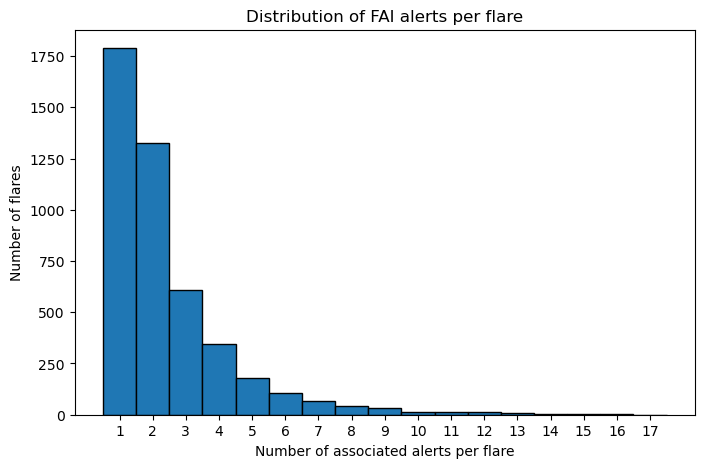

In [31]:
import matplotlib.pyplot as plt


# Histograma del número de alertas por flare
plt.figure(figsize=(8,5))
plt.hist(df_anticipation_time['FAIalerts_W'], 
         bins=range(1, df_anticipation_time['FAIalerts_W'].max()+2),
         edgecolor='black', align='left')
plt.xlabel('Number of associated alerts per flare')
plt.ylabel('Number of flares')
plt.title('Distribution of FAI alerts per flare')
plt.xticks(range(1, df_anticipation_time['FAIalerts_W'].max()+1))
plt.show()


In [32]:
import matplotlib.pyplot as plt

def plot_alerts_per_flare_by_class(df, flare_class, class_col='ClassGroup', alert_col='FAIalerts_W'):
    """
    Genera un histograma del número de alertas asociadas por flare
    filtrando por la clase de flare (C, M o X).

    Parámetros:
    - df: DataFrame con los datos de los flares.
    - flare_class: clase de flare a filtrar ('C', 'M', 'X').
    - class_col: nombre de la columna con la clase de flare (default 'F_ClassGroup').
    - alert_col: nombre de la columna con el número de alertas asociadas (default 'FAIalerts_W').
    """
    # Filtrar por la clase de flare
    df_class = df[df[class_col] == flare_class]

    if df_class.empty:
        print(f"No data for flare class {flare_class}")
        return

    # Histograma
    plt.figure(figsize=(8,5))
    plt.hist(df_class[alert_col],
             bins=range(1, df_class[alert_col].max()+2),
             edgecolor='black', align='left')
    plt.xlabel('Number of associated alerts per flare')
    plt.ylabel('Number of flares')
    plt.title(f'Distribution of FAI alerts per flare - Class {flare_class}')
    plt.xticks(range(1, df_class[alert_col].max()+1))
    plt.show()


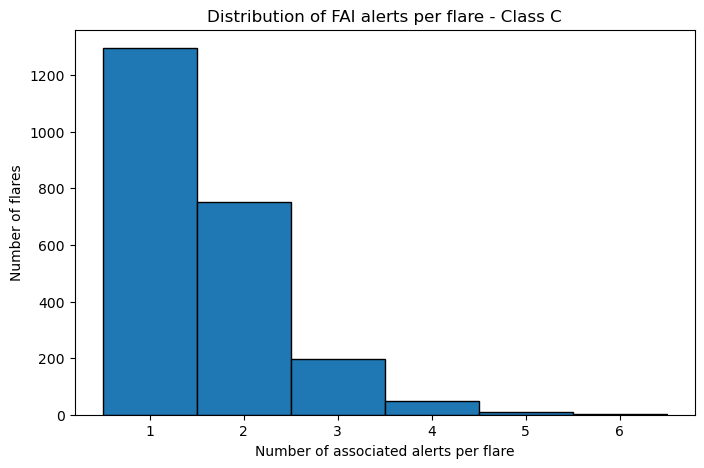

In [33]:
plot_alerts_per_flare_by_class(df=df_anticipation_time,
                               flare_class='C', 
                               class_col='ClassLetter', 
                               alert_col='FAIalerts_W')



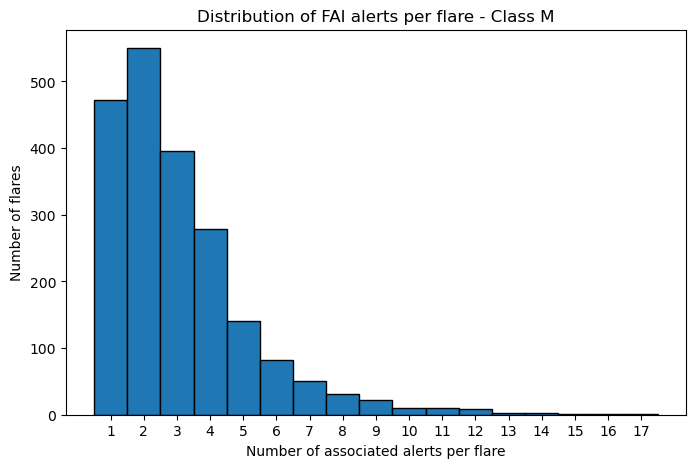

In [34]:
plot_alerts_per_flare_by_class(df=df_anticipation_time,
                               flare_class='M', 
                               class_col='ClassLetter', 
                               alert_col='FAIalerts_W')


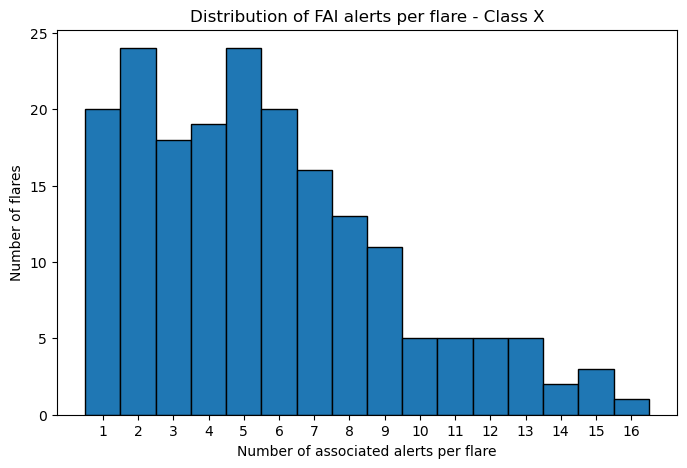

In [35]:
plot_alerts_per_flare_by_class(df=df_anticipation_time,
                               flare_class='X', 
                               class_col='ClassLetter', 
                               alert_col='FAIalerts_W')


In [36]:
df_anticipation_time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48344 entries, 0 to 48343
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Flare_ID                    48344 non-null  object        
 1   StartTime                   48344 non-null  datetime64[ns]
 2   PeakTime                    48344 non-null  datetime64[ns]
 3   EndTime                     48344 non-null  datetime64[ns]
 4   StartPeak                   48344 non-null  float64       
 5   StartEnd                    48344 non-null  float64       
 6   PeakEnd                     48344 non-null  float64       
 7   Class                       48344 non-null  object        
 8   ClassLetter                 48344 non-null  object        
 9   ClassNumber                 48344 non-null  float64       
 10  ClassGroup                  48344 non-null  object        
 11  NOAA_Class                  0 non-null      float64   

In [37]:
df_anticipation_time['AnticipationPeak'].count()

np.int64(4560)

In [38]:
df_anticipation_time['AnticipationPeak'].unique()


array([         nan,   1.        ,  13.        ,  22.        ,
         2.        ,   3.        ,   5.        ,  12.        ,
        16.        ,  66.        ,   6.        ,  14.        ,
         8.        ,   9.        ,  24.        ,  30.        ,
        21.        ,  18.        ,  31.        ,  11.        ,
        20.        ,   7.        ,  68.        ,  19.        ,
         4.        ,  10.        ,  15.        ,  63.        ,
        36.        ,  27.        ,  64.        ,  29.        ,
        43.        ,  17.        ,  33.        ,  44.        ,
        26.        ,  59.        ,  42.        ,  47.        ,
       105.        ,  86.        ,  25.        ,  52.        ,
        23.        ,  57.        ,  35.        ,  55.        ,
        37.        , 179.        ,  34.        ,  51.        ,
        41.        ,  97.        ,  28.        ,  40.        ,
        32.        , 152.        ,  81.        ,  39.        ,
        69.        ,  65.        , 121.        ,  60.  

In [39]:
import matplotlib.pyplot as plt
import numpy as np

def plot_anticipation_time_per_flare_by_class(df, flare_class, class_col='ClassGroup', alert_col='AnticipationPeak'):
    """
    Genera un histograma del tiempo de anticipación por flare
    filtrando por la clase de flare (C, M o X).

    Parámetros:
    - df: DataFrame con los datos de los flares.
    - flare_class: clase de flare a filtrar ('C', 'M', 'X').
    - class_col: nombre de la columna con la clase de flare (default 'ClassGroup').
    - alert_col: nombre de la columna con el tiempo de anticipación (default 'AnticipationPeak').
    """
    # Filtrar por la clase de flare
    df_class = df[df[class_col] == flare_class]

    if df_class.empty:
        print(f"No data for flare class {flare_class}")
        return

    # Tomar los valores no nulos y redondearlos a entero
    anticipation_values = df_class[alert_col].dropna().round().astype(int)

    if anticipation_values.empty:
        print(f"No valid {alert_col} values for flare class {flare_class}")
        return

    # Definir bins para enteros
    bins = np.arange(0, anticipation_values.max() + 2, 1)  # 1 min por bin

    # Histograma
    plt.figure(figsize=(8,5))
    plt.hist(anticipation_values, bins=bins, edgecolor='black', align='left')
    plt.xlabel('Anticipation time (min)')
    plt.ylabel('Number of flares')
    plt.title(f'Distribution of Anticipation time per flare - Class {flare_class} ({alert_col})')
    plt.xticks(range(0, anticipation_values.max() + 1, max(1, anticipation_values.max()//10)))  # ajustar ticks
    plt.show()


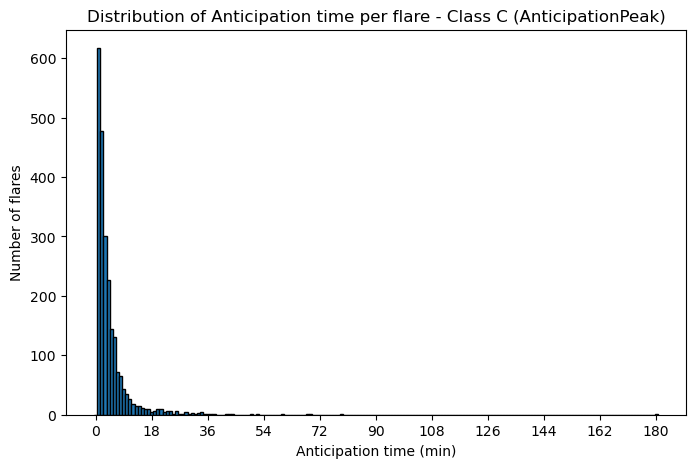

In [40]:
plot_anticipation_time_per_flare_by_class(df=df_anticipation_time,
                                          flare_class='C',
                                          class_col='ClassLetter', 
                                          alert_col='AnticipationPeak')

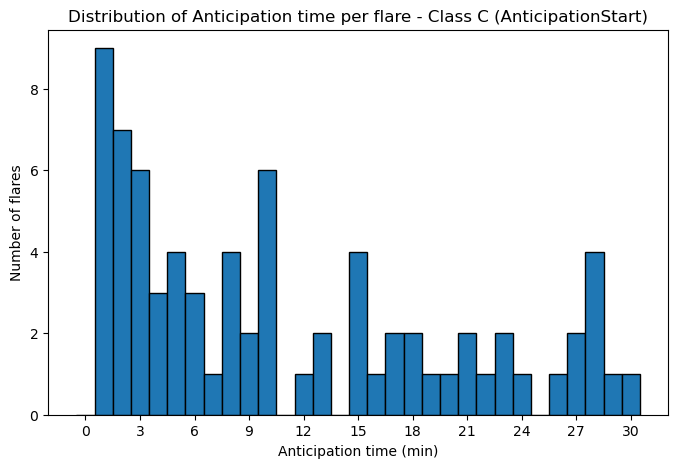

In [41]:
plot_anticipation_time_per_flare_by_class(df=df_anticipation_time,
                                          flare_class='C',
                                          class_col='ClassLetter', 
                                          alert_col='AnticipationStart')

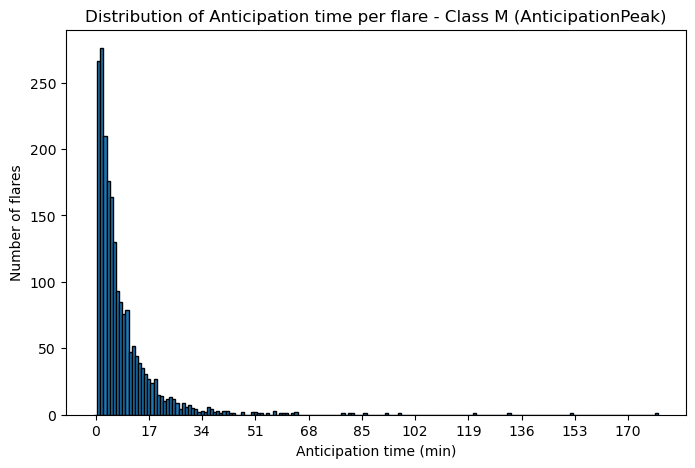

In [42]:
plot_anticipation_time_per_flare_by_class(df=df_anticipation_time,
                                          flare_class='M',
                                          class_col='ClassLetter', 
                                          alert_col='AnticipationPeak')

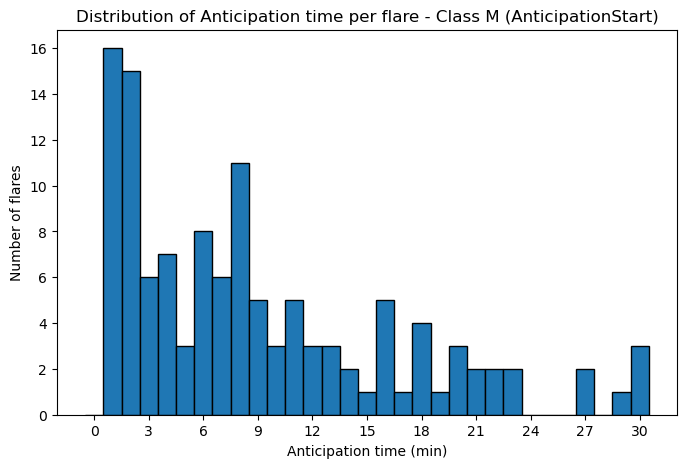

In [43]:
plot_anticipation_time_per_flare_by_class(df=df_anticipation_time,
                                          flare_class='M',
                                          class_col='ClassLetter', 
                                          alert_col='AnticipationStart')

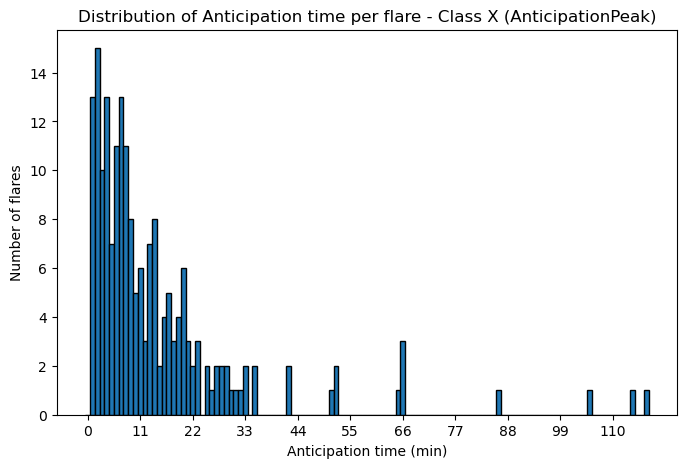

In [44]:
plot_anticipation_time_per_flare_by_class(df=df_anticipation_time,
                                          flare_class='X',
                                          class_col='ClassLetter', 
                                          alert_col='AnticipationPeak')

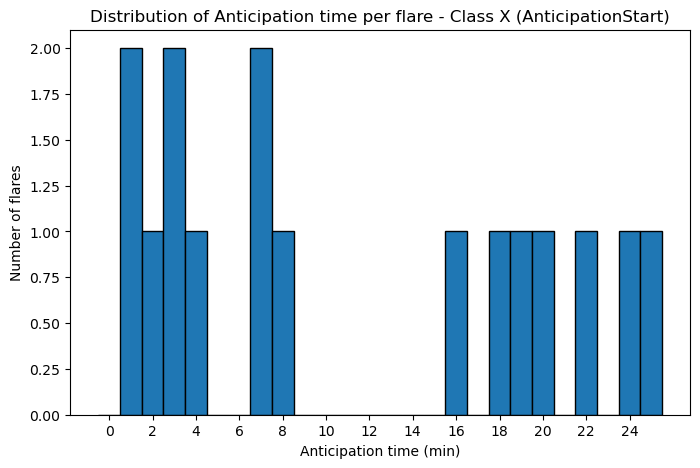

In [45]:
plot_anticipation_time_per_flare_by_class(df=df_anticipation_time,
                                          flare_class='X',
                                          class_col='ClassLetter', 
                                          alert_col='AnticipationStart')

### flares sin alerta clase M

In [46]:
# Filtrar y ordenar
resultadoMsinFAI = df_anticipation_time[
    (df_anticipation_time['FAIalerts_W'] == 0) & 
    (df_anticipation_time['ClassGroup'] == 'M5-9.9')
].sort_values(by='Class', ascending=False)

len(resultadoMsinFAI)

60

In [47]:
# Filtrar y ordenar
resultadomsinFAI = df_anticipation_time[
    (df_anticipation_time['FAIalerts_W'] == 0) & 
    (df_anticipation_time['ClassGroup'] == 'M1-4.9')
].sort_values(by='Class', ascending=False)

len(resultadomsinFAI)

1227

In [48]:
# Filtrar y ordenar
resultadoMsinFAI = df_anticipation_time[
    (df_anticipation_time['FAIalerts_W'] == 0) & 
    (df_anticipation_time['ClassLetter'] == 'M')
].sort_values(by='Class', ascending=False)

resultadoMsinFAI.iloc[:10]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
11126,199110242236_M9.8,1991-10-24 21:56:00,1991-10-24 22:36:00,1991-10-25 00:15:00,40.0,139.0,99.0,M9.8,M,9.8,M5-9.9,NaN,NaN,GOES,GOES,NaN,6891.0,NaN,NaN,NaN,-680.5740,-258.6108,-46.0,-12.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,91.0,93.0,NaN,NaN
7187,198911081902_M9.8,1989-11-08 18:56:00,1989-11-08 19:02:00,1989-11-08 20:36:00,6.0,100.0,94.0,M9.8,M,9.8,M5-9.9,NaN,NaN,GOES,GOES,NaN,5769.0,NaN,NaN,NaN,764.8680,300.6642,57.0,20.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,43.0,87.0,NaN,NaN
19100,199908202308_M9.8,1999-08-20 23:03:00,1999-08-20 23:08:00,1999-08-20 23:10:00,5.0,7.0,2.0,M9.8,M,9.8,M5-9.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.0000,-114.1020,0.0,0.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,122.0,127.0,NaN,NaN
242,198011130037_M9.4,1980-11-13 00:31:00,1980-11-13 00:37:00,1980-11-13 01:24:00,6.0,53.0,47.0,M9.4,M,9.4,M5-9.9,NaN,NaN,GOES,GOES,NaN,2779.0,NaN,NaN,NaN,342.3912,-232.4934,21.0,-11.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,72.0,114.0,NaN,NaN
30103,201107300209_M9.3,2011-07-30 02:04:00,2011-07-30 02:09:00,2011-07-30 02:12:00,5.0,8.0,3.0,M9.3,M,9.3,M5-9.9,NaN,NaN,GOES,GOES,NaN,11261.0,NaN,NaN,NaN,0.0000,-92.6292,0.0,0.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,73.0,76.0,NaN,NaN
34027,201403122234_M9.3,2014-03-12 22:28:00,2014-03-12 22:34:00,2014-03-12 22:39:00,6.0,11.0,5.0,M9.3,M,9.3,M5-9.9,NaN,NaN,GOES,GOES,NaN,11996.0,NaN,NaN,NaN,912.4260,272.3004,78.0,15.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1086,198207080653_M8.8,1982-07-08 06:50:00,1982-07-08 06:53:00,1982-07-08 07:17:00,3.0,27.0,24.0,M8.8,M,8.8,M5-9.9,NaN,NaN,GOES,GOES,NaN,3804.0,NaN,NaN,NaN,-928.5480,161.4336,-88.0,10.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,89.0,101.0,NaN,NaN
13912,199304181909_M8.7,1993-04-18 19:07:00,1993-04-18 19:09:00,1993-04-18 20:11:00,2.0,64.0,62.0,M8.7,M,8.7,M5-9.9,NaN,NaN,GOES,GOES,NaN,7477.0,NaN,NaN,NaN,-772.1940,215.3526,-55.0,10.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,25.0,44.0,NaN,NaN
1138,198207170206_M8.5,1982-07-17 02:03:00,1982-07-17 02:06:00,1982-07-17 03:22:00,3.0,79.0,76.0,M8.5,M,8.5,M5-9.9,NaN,NaN,GOES,GOES,NaN,3804.0,NaN,NaN,NaN,519.8748,119.3736,34.0,11.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26109,200501150431_M8.4,2005-01-15 04:26:00,2005-01-15 04:31:00,2005-01-15 04:36:00,5.0,10.0,5.0,M8.4,M,8.4,M5-9.9,NaN,NaN,GOES,GOES,NaN,10720.0,NaN,NaN,NaN,-99.3180,311.6640,-6.0,14.0,FL,9,0,0,0,0,0,0,NaN,NaN,NaN,34.0,51.0,NaN,NaN


## Qué pasa con los FAIs que no están siendo asociados (FP)

In [49]:
df_fai_assoc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12431 entries, 0 to 12430
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 12431 non-null  object 
 1   observatory          12431 non-null  object 
 2   xrsa                 12431 non-null  float64
 3   xrsb                 12431 non-null  float64
 4   xrsa_corr            12431 non-null  float64
 5   xrsb_corr            12431 non-null  float64
 6   T_cor                12431 non-null  float64
 7   EM_cor               12431 non-null  float64
 8   T_phot               12431 non-null  float64
 9   EM_phot              12431 non-null  float64
 10  EM_cor_norm          12431 non-null  float64
 11  EM_phot_norm         12431 non-null  float64
 12  month                12431 non-null  int64  
 13  day                  12431 non-null  object 
 14  GOES_missing         12431 non-null  bool   
 15  EM_diff              12431 non-null 

In [50]:
df_fai_assoc.head()

,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing,EM_diff,EM_jump,FAI_alert,FAI_true,delta_min,group_id,duration_from_start,Time_FAI,Associated_Flare,Flare_ID,F_StartTime,F_PeakTime,F_EndTime,F_Class,F_ClassLetter,F_ClassNumber,F_ClassGroup,F_Observatory,F_StartPeak,F_PeakEnd,F_StartEnd,Association_Type,Time_to_flare,FAI_to_start,FAI_to_peak,FAI_to_end
0,1980-04-26 01:01:00,GOES-2,6.047950e-07,0.000006,5.681170e-07,0.000004,12.577171,1.615648e+48,11.621733,3.948256e+48,0.161565,0.394826,4,1980-04-26,False,0.034015,True,True,True,1.0,159,3.0,1980-04-26 01:01:00,True,198004260102_C7.0,1980-04-26 00:59:00,1980-04-26 01:02:00,1980-04-26 01:17:00,C7.0,C,7.0,C5-9.9,GOES,3.0,15.0,18.0,PeakTime,1.0,-2.0,1.0,16.0
1,1980-04-26 03:32:00,GOES-2,2.676300e-06,0.000017,2.659787e-06,0.000016,13.829559,5.597570e+48,13.099952,1.263184e+49,0.559757,1.263184,4,1980-04-26,False,0.312863,True,True,True,1.0,169,3.0,1980-04-26 03:32:00,True,198004260345_M2.0,1980-04-26 03:30:00,1980-04-26 03:45:00,1980-04-26 04:12:00,M2.0,M,2.0,M1-4.9,GOES,15.0,27.0,42.0,PeakTime,13.0,-2.0,13.0,40.0
2,1980-04-26 03:33:00,GOES-2,4.089263e-06,0.000021,4.067714e-06,0.000020,14.854798,6.899529e+48,14.341419,1.470020e+49,0.689953,1.470020,4,1980-04-26,False,0.130196,True,True,True,1.0,169,4.0,1980-04-26 03:33:00,True,198004260345_M2.0,1980-04-26 03:30:00,1980-04-26 03:45:00,1980-04-26 04:12:00,M2.0,M,2.0,M1-4.9,GOES,15.0,27.0,42.0,PeakTime,12.0,-3.0,12.0,39.0
3,1980-04-26 06:05:00,GOES-2,6.579550e-07,0.000008,6.248550e-07,0.000005,11.676478,2.265801e+48,10.602302,5.888671e+48,0.226580,0.588867,4,1980-04-26,False,0.015164,True,True,True,1.0,180,3.0,1980-04-26 06:05:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1980-04-26 07:22:00,GOES-2,4.976368e-07,0.000006,4.481516e-07,0.000004,11.649372,1.637552e+48,10.572428,4.263903e+48,0.163755,0.426390,4,1980-04-26,False,0.032621,True,True,True,1.0,185,3.0,1980-04-26 07:22:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [51]:
df_fai_assoc['observatory'].value_counts()


observatory
GOES-6     3346
GOES-10    2642
GOES-15    2193
GOES-18    2056
GOES-12    1064
GOES-2      324
GOES-17     276
GOES-9      162
GOES-5      158
GOES-7       74
GOES-14      72
GOES-16      32
GOES-11      22
GOES-13      10
Name: count, dtype: int64

In [52]:
df_fai_assoc['Associated_Flare'].value_counts()


Associated_Flare
True     11043
False     1388
Name: count, dtype: int64

In [53]:
df_fai_assoc.groupby(['observatory', 'Associated_Flare']).size().unstack(fill_value=0)


Associated_Flare,False,True
observatory,,
GOES-10,263,2379
GOES-11,6,16
GOES-12,112,952
GOES-13,0,10
GOES-14,8,64
GOES-15,308,1885
GOES-16,4,28
GOES-17,23,253
GOES-18,285,1771


In [54]:
table = df_fai_assoc.groupby(['observatory', 'Associated_Flare']) \
                    .size() \
                    .unstack(fill_value=0)

# Extraer número del satélite
table['sat_num'] = table.index.str.extract(r'GOES-(\d+)', expand=False).astype(int)

# Ordenar por ese número
table_sorted = table.sort_values('sat_num').drop(columns='sat_num')

table_sorted


Associated_Flare,False,True
observatory,,
GOES-2,51,273
GOES-5,17,141
GOES-6,303,3043
GOES-7,0,74
GOES-9,8,154
GOES-10,263,2379
GOES-11,6,16
GOES-12,112,952
GOES-13,0,10


In [55]:
# 1. Tabla de conteos
table = df_fai_assoc.groupby(['observatory', 'Associated_Flare']) \
                    .size() \
                    .unstack(fill_value=0)

# 2. Extraer número del satélite para ordenar
table['sat_num'] = table.index.str.extract(r'GOES-(\d+)', expand=False).astype(int)
table = table.sort_values('sat_num').drop(columns='sat_num')

# 3. Calcular porcentajes por satélite
total = table.sum(axis=1)  # total por satélite
table['False_%'] = (table[False] / total) * 100
table['True_%']  = (table[True]  / total) * 100

# 4. Resultado final
table_sorted = table
table_sorted


Associated_Flare,False,True,False_%,True_%
observatory,,,,
GOES-2,51,273,15.740741,84.259259
GOES-5,17,141,10.759494,89.240506
GOES-6,303,3043,9.055589,90.944411
GOES-7,0,74,0.000000,100.000000
GOES-9,8,154,4.938272,95.061728
GOES-10,263,2379,9.954580,90.045420
GOES-11,6,16,27.272727,72.727273
GOES-12,112,952,10.526316,89.473684
GOES-13,0,10,0.000000,100.000000


In [56]:
# Asegurar que la columna 'date' sea datetime
df_fai_assoc['date'] = pd.to_datetime(df_fai_assoc['date'], errors='coerce')

# 1. Tabla de conteos
table = df_fai_assoc.groupby(['observatory', 'Associated_Flare']) \
                    .size() \
                    .unstack(fill_value=0)

# 2. Ordenar por número de GOES
table['sat_num'] = table.index.str.extract(r'GOES-(\d+)', expand=False).astype(int)
table = table.sort_values('sat_num').drop(columns='sat_num')

# 3. Porcentajes
total = table.sum(axis=1)
table['False_%'] = (table[False] / total) * 100
table['True_%']  = (table[True]  / total) * 100

# 4. Fechas mínima y máxima por satélite
date_ranges = df_fai_assoc.groupby('observatory')['date'].agg(['min', 'max'])

# 5. Unir tablas
table = table.join(date_ranges)

# 6. (Opcional) Redondear porcentajes
table[['False_%', 'True_%']] = table[['False_%', 'True_%']].round(2)

table


,False,True,False_%,True_%,min,max
observatory,,,,,,
GOES-2,51,273,15.74,84.26,1980-04-26 01:01:00,1983-01-27 03:37:00
GOES-5,17,141,10.76,89.24,1983-05-22 10:10:00,1984-05-22 15:00:00
GOES-6,303,3043,9.06,90.94,1983-06-06 07:53:00,1993-12-29 22:59:00
GOES-7,0,74,0.00,100.00,1994-01-02 22:54:00,1995-10-20 05:59:00
GOES-9,8,154,4.94,95.06,1996-05-05 18:35:00,1998-07-05 11:39:00
GOES-10,263,2379,9.95,90.05,1998-07-11 12:49:00,2003-01-08 05:48:00
GOES-11,6,16,27.27,72.73,2007-05-02 23:39:00,2007-12-31 00:50:00
GOES-12,112,952,10.53,89.47,2003-01-21 05:56:00,2007-01-16 02:35:00
GOES-13,0,10,0.00,100.00,2014-02-08 18:30:00,2014-12-28 17:57:00


In [57]:
# Ver distribución de todos los valores
distribucion = df_fai_assoc['Association_Type'].value_counts().sort_index()
print("Distribución de Association_Type:")
print(distribucion)


Distribución de Association_Type:
Association_Type
Inside         237
PeakTime     10285
StartTime      521
Name: count, dtype: int64


In [58]:
total = len(df_fai_assoc)
con_valor = df_fai_assoc['Association_Type'].notna().sum()
sin_valor = df_fai_assoc['Association_Type'].isna().sum()

print("Total filas:", total)
print("Con Association_Type:", con_valor)
print("Sin Association_Type:", sin_valor)

Total filas: 12431
Con Association_Type: 11043
Sin Association_Type: 1388


## filtro de FAI sin asociación

In [59]:
df_sin_asoc = df_fai_assoc[df_fai_assoc['Association_Type'].isna()]


In [60]:
df_sin_asoc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1388 entries, 3 to 12429
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   date                 1388 non-null   datetime64[ns]
 1   observatory          1388 non-null   object        
 2   xrsa                 1388 non-null   float64       
 3   xrsb                 1388 non-null   float64       
 4   xrsa_corr            1388 non-null   float64       
 5   xrsb_corr            1388 non-null   float64       
 6   T_cor                1388 non-null   float64       
 7   EM_cor               1388 non-null   float64       
 8   T_phot               1388 non-null   float64       
 9   EM_phot              1388 non-null   float64       
 10  EM_cor_norm          1388 non-null   float64       
 11  EM_phot_norm         1388 non-null   float64       
 12  month                1388 non-null   int64         
 13  day                  1388 non-null   

In [61]:
df_sin_asoc.head()

,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing,EM_diff,EM_jump,FAI_alert,FAI_true,delta_min,group_id,duration_from_start,Time_FAI,Associated_Flare,Flare_ID,F_StartTime,F_PeakTime,F_EndTime,F_Class,F_ClassLetter,F_ClassNumber,F_ClassGroup,F_Observatory,F_StartPeak,F_PeakEnd,F_StartEnd,Association_Type,Time_to_flare,FAI_to_start,FAI_to_peak,FAI_to_end
3,1980-04-26 06:05:00,GOES-2,6.579550e-07,0.000008,6.248550e-07,0.000005,11.676478,2.265801e+48,10.602302,5.888671e+48,0.226580,0.588867,4,1980-04-26,False,0.015164,True,True,True,1.0,180,3.0,1980-04-26 06:05:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1980-04-26 07:22:00,GOES-2,4.976368e-07,0.000006,4.481516e-07,0.000004,11.649372,1.637552e+48,10.572428,4.263903e+48,0.163755,0.426390,4,1980-04-26,False,0.032621,True,True,True,1.0,185,3.0,1980-04-26 07:22:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1980-06-05 00:26:00,GOES-2,9.010000e-07,0.000010,7.570500e-07,0.000006,12.355744,2.280756e+48,11.366936,5.657047e+48,0.228076,0.565705,6,1980-06-05,False,0.057648,True,True,True,1.0,596,3.0,1980-06-05 00:26:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1980-06-05 00:27:00,GOES-2,1.087895e-06,0.000012,8.543159e-07,0.000007,11.989174,2.840066e+48,10.950850,7.222635e+48,0.284007,0.722264,6,1980-06-05,False,0.055931,True,True,True,1.0,596,4.0,1980-06-05 00:27:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,1980-08-24 19:49:00,GOES-2,1.946900e-06,0.000015,1.848804e-06,0.000012,13.390932,4.303187e+48,12.577277,9.971484e+48,0.430319,0.997148,8,1980-08-24,False,0.057471,True,True,True,1.0,1412,3.0,1980-08-24 19:49:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
# Ver distribución de todos los valores
distribucion = df_sin_asoc['FAI_true'].value_counts().sort_index()
print("Distribución de FAI_true:")
print(distribucion)

Distribución de FAI_true:
FAI_true
True    1388
Name: count, dtype: int64


In [63]:
df_sin_asoc.iloc[4:10]

,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing,EM_diff,EM_jump,FAI_alert,FAI_true,delta_min,group_id,duration_from_start,Time_FAI,Associated_Flare,Flare_ID,F_StartTime,F_PeakTime,F_EndTime,F_Class,F_ClassLetter,F_ClassNumber,F_ClassGroup,F_Observatory,F_StartPeak,F_PeakEnd,F_StartEnd,Association_Type,Time_to_flare,FAI_to_start,FAI_to_peak,FAI_to_end
17,1980-08-24 19:49:00,GOES-2,0.000002,0.000015,1.848804e-06,0.000012,13.390932,4.303187e+48,12.577277,9.971484e+48,0.430319,0.997148,8,1980-08-24,False,0.057471,True,True,True,1.0,1412,3.0,1980-08-24 19:49:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,1980-08-24 19:50:00,GOES-2,0.000002,0.000020,2.094889e-06,0.000015,12.546214,6.005309e+48,11.585957,1.470595e+49,0.600531,1.470595,8,1980-08-24,False,0.170212,True,True,True,1.0,1412,4.0,1980-08-24 19:50:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41,1980-11-06 19:22:00,GOES-2,0.000001,0.000012,6.838550e-07,0.000004,14.638107,1.211300e+48,14.076860,2.610987e+48,0.121130,0.261099,11,1980-11-06,False,0.024481,True,True,True,1.0,2164,3.0,1980-11-06 19:22:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,1980-11-06 19:42:00,GOES-2,0.000010,0.000040,7.874106e-06,0.000023,19.561724,6.560603e+48,20.499421,1.138005e+49,0.656060,1.138005,11,1980-11-06,False,0.211868,True,True,True,1.0,2169,3.0,1980-11-06 19:42:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,1980-11-06 19:43:00,GOES-2,0.000012,0.000047,1.013945e-05,0.000030,19.557883,8.451802e+48,20.494037,1.466259e+49,0.845180,1.466259,11,1980-11-06,False,0.189120,True,True,True,1.0,2169,4.0,1980-11-06 19:43:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
44,1980-11-06 19:44:00,GOES-2,0.000014,0.000053,1.113510e-05,0.000033,19.171196,9.713562e+48,19.955158,1.709452e+49,0.971356,1.709452,11,1980-11-06,False,0.126176,True,True,True,1.0,2169,5.0,1980-11-06 19:44:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [64]:
# Extraer año
df_fai_assoc['year'] = df_fai_assoc['date'].dt.year

# 1. Tabla de conteos por año
table_year = df_fai_assoc.groupby(['year', 'Associated_Flare']).size().unstack(fill_value=0)

# 2. Porcentajes
total_year = table_year.sum(axis=1)
table_year['False_%'] = (table_year[False] / total_year) * 100
table_year['True_%']  = (table_year[True]  / total_year) * 100

# 3. Fecha mínima y máxima por año
date_ranges_year = df_fai_assoc.groupby('year')['date'].agg(['min', 'max'])

# 4. Contar días únicos por año
days_count = df_fai_assoc.groupby('year')['date'].apply(lambda x: x.dt.date.nunique())
days_count.name = 'Unique_Days'

# 5. Unir todo
table_year = table_year.join(date_ranges_year).join(days_count)

# 6. Redondear porcentajes
table_year[['False_%', 'True_%']] = table_year[['False_%', 'True_%']].round(2)

# 7. Ordenar por año
table_year = table_year.sort_index()

table_year

,False,True,False_%,True_%,min,max,Unique_Days
year,,,,,,,
1980,11,56,16.42,83.58,1980-04-26 01:01:00,1980-12-27 10:17:00,11
1981,8,69,10.39,89.61,1981-01-05 16:17:00,1981-11-18 04:16:00,20
1982,32,145,18.08,81.92,1982-01-02 00:48:00,1982-12-26 00:15:00,39
1983,16,46,25.81,74.19,1983-01-27 03:35:00,1983-12-17 22:45:00,23
1984,5,118,4.07,95.93,1984-01-27 06:58:00,1984-11-10 04:37:00,26
1985,0,5,0.00,100.00,1985-05-13 09:29:00,1985-05-13 09:33:00,1
1986,0,10,0.00,100.00,1986-02-07 10:19:00,1986-10-19 00:29:00,3
1987,3,36,7.69,92.31,1987-04-15 07:35:00,1987-12-27 07:18:00,12
1988,34,281,10.79,89.21,1988-01-02 21:28:00,1988-12-28 20:56:00,78


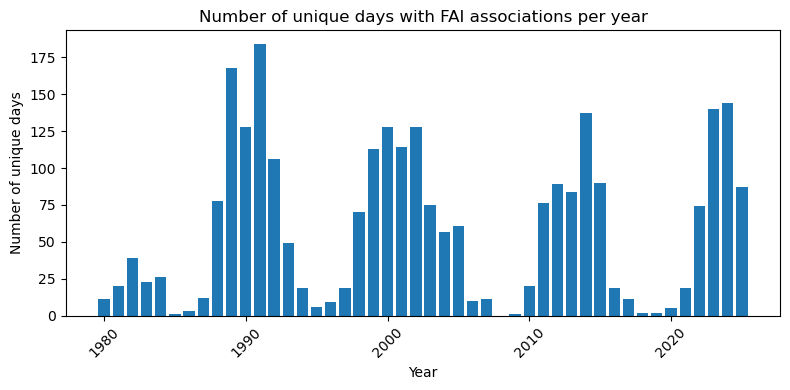

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(table_year.index, table_year['Unique_Days'])

plt.xlabel("Year")
plt.ylabel("Number of unique days")
plt.title("Number of unique days with FAI associations per year")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


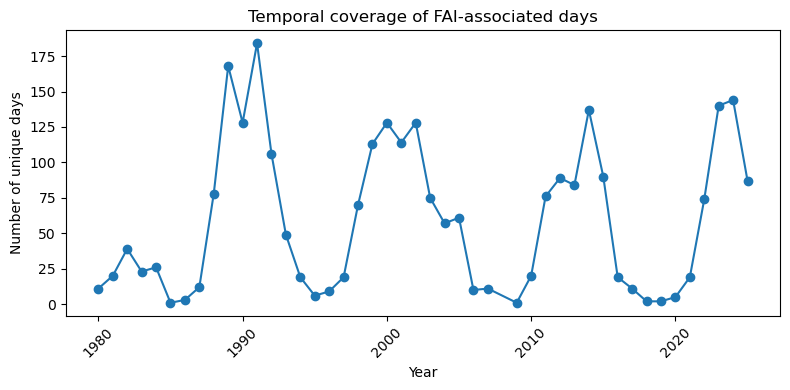

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(table_year.index, table_year['Unique_Days'], marker='o')

plt.xlabel("Year")
plt.ylabel("Number of unique days")
plt.title("Temporal coverage of FAI-associated days")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


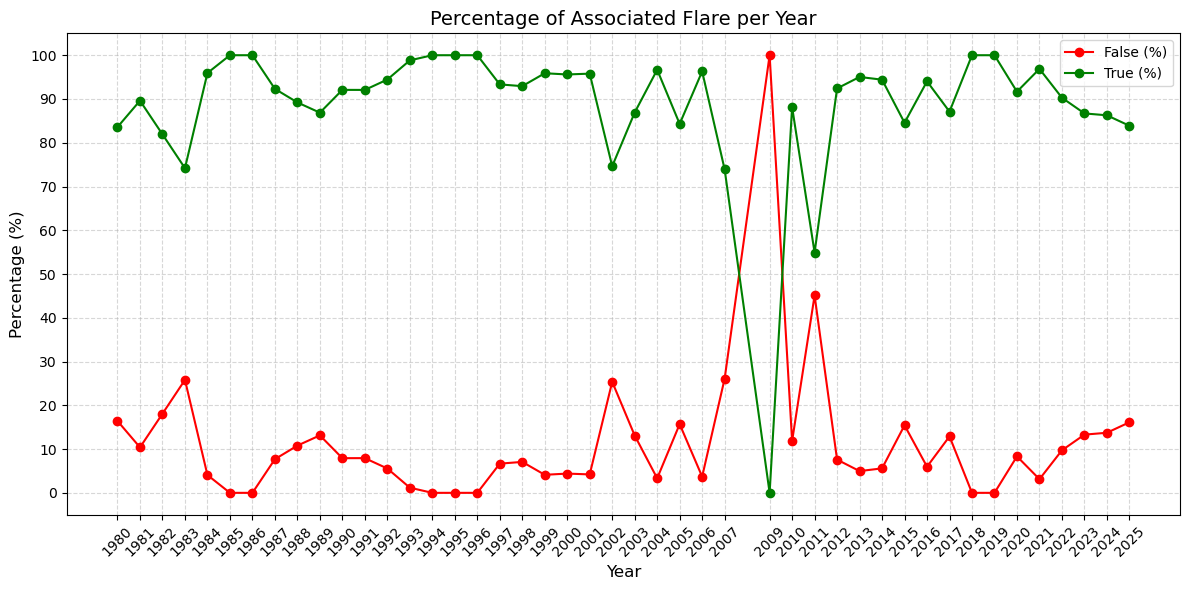

In [67]:
import matplotlib.pyplot as plt

# Asegurarnos de que la tabla por año ya esté lista
# table_year debe tener columnas: False_%, True_%

years = table_year.index
false_pct = table_year['False_%']
true_pct  = table_year['True_%']

plt.figure(figsize=(12,6))
plt.plot(years, false_pct, marker='o', label='False (%)', color='red')
plt.plot(years, true_pct, marker='o', label='True (%)', color='green')

plt.xlabel('Year', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.title('Percentage of Associated Flare per Year', fontsize=14)
plt.xticks(years, rotation=45)
plt.yticks(range(0, 101, 10))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()



## FAIs asociados que estan seguidos

In [68]:
df_asoc = df_fai_assoc[df_fai_assoc['Association_Type'].notna()]


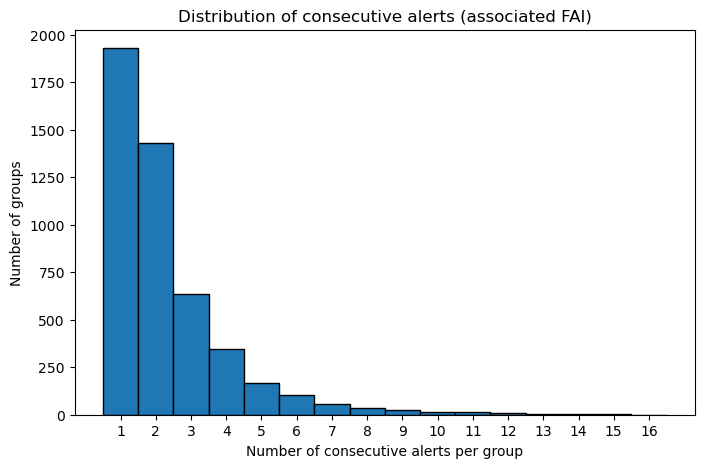

In [69]:
import matplotlib.pyplot as plt

# Contar cuántas alertas hay por grupo (solo asociados)
conteo_por_grupo_asoc = df_asoc.groupby('group_id').size()

# Histograma
plt.figure(figsize=(8,5))
plt.hist(conteo_por_grupo_asoc, bins=range(1, conteo_por_grupo_asoc.max()+2),
         edgecolor='black', align='left')
plt.xlabel('Number of consecutive alerts per group')
plt.ylabel('Number of groups')
plt.title('Distribution of consecutive alerts (associated FAI)')
plt.xticks(range(1, conteo_por_grupo_asoc.max()+1))
plt.show()


## revisión Fais no asociados que estan seguidos

In [70]:
# Contar cuántas alertas hay por grupo
conteo_por_grupo = df_sin_asoc.groupby('group_id').size()

# Mostrar los primeros 10 grupos
#print(conteo_por_grupo.head(10))

conteo_por_grupo_df = conteo_por_grupo.reset_index(name='count').sort_values('count', ascending=False)
print(conteo_por_grupo_df.head(200))


     group_id  count
573    351816     15
312    215465     14
365    234401     13
315    217037     13
373    234461     12
..        ...    ...
11       7692      2
2         596      2
546    337783      2
3        1412      2
9        4289      2

[200 rows x 2 columns]


In [71]:
# Filtrar los que solo tienen 1 alerta
grupos_solitarios = conteo_por_grupo[conteo_por_grupo == 1]

# Cantidad de grupos con solo 1 alerta
print("Número de grupos con una sola alerta:", len(grupos_solitarios))


Número de grupos con una sola alerta: 247


In [72]:
# Filtrar los que solo tienen 1 alerta
grupos_2 = conteo_por_grupo[conteo_por_grupo == 2]

# Cantidad de grupos con solo 2 alertas
print("Número de grupos con 2 alertas:", len(grupos_2))


Número de grupos con 2 alertas: 154


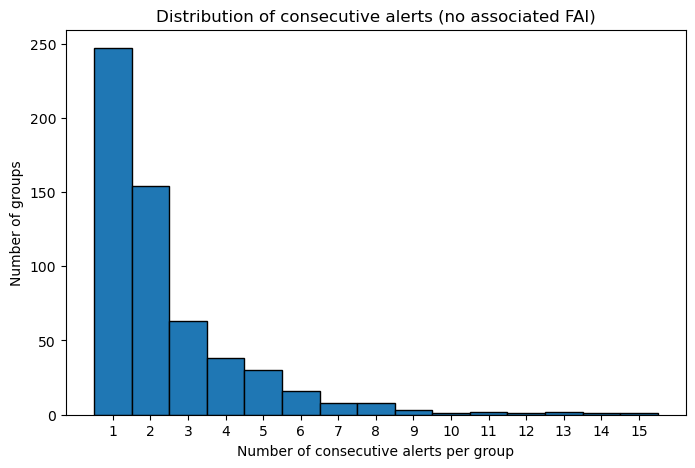

In [73]:
import matplotlib.pyplot as plt

# Contar cuántas alertas hay por grupo
conteo_por_grupo = df_sin_asoc.groupby('group_id').size()

# Hacer histograma del número de alertas consecutivas
plt.figure(figsize=(8,5))
plt.hist(conteo_por_grupo, bins=range(1, conteo_por_grupo.max()+2), 
         edgecolor='black', align='left')
plt.xlabel('Number of consecutive alerts per group')
plt.ylabel('Number of groups')
plt.title('Distribution of consecutive alerts (no associated FAI)')
plt.xticks(range(1, conteo_por_grupo.max()+1))
plt.show()


In [74]:
# Contar cuántas alertas hay por grupo
counts = df_sin_asoc.groupby('group_id').size()

# Filtrar grupos con más de una alerta (es decir, alertas seguidas)
groups_seguidos = counts[counts == 9].index

# Obtener las filas correspondientes
df_seguidos = df_sin_asoc[df_sin_asoc['group_id'].isin(groups_seguidos)]
df_seguidos


,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing,EM_diff,EM_jump,FAI_alert,FAI_true,delta_min,group_id,duration_from_start,Time_FAI,Associated_Flare,Flare_ID,F_StartTime,F_PeakTime,F_EndTime,F_Class,F_ClassLetter,F_ClassNumber,F_ClassGroup,F_Observatory,F_StartPeak,F_PeakEnd,F_StartEnd,Association_Type,Time_to_flare,FAI_to_start,FAI_to_peak,FAI_to_end
1028,1989-01-18 06:12:00,GOES-6,6.842105e-07,0.000006,5.606316e-07,0.000002,16.597946,1.008044e+48,16.523981,1.975005e+48,0.100804,0.197500,1,1989-01-18,False,0.030820,True,True,True,1.0,44157,3.0,1989-01-18 06:12:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1029,1989-01-18 06:13:00,GOES-6,9.874500e-07,0.000008,7.777000e-07,0.000003,16.417323,1.440067e+48,16.293060,2.844779e+48,0.144007,0.284478,1,1989-01-18,False,0.043202,True,True,True,1.0,44157,4.0,1989-01-18 06:13:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1030,1989-01-18 06:14:00,GOES-6,1.899000e-06,0.000009,1.684647e-06,0.000005,21.405990,1.658874e+48,23.142555,2.705106e+48,0.165887,0.270511,1,1989-01-18,False,0.021881,True,True,True,1.0,44157,5.0,1989-01-18 06:14:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1031,1989-01-18 06:15:00,GOES-6,1.933750e-06,0.000011,1.627697e-06,0.000006,17.624543,2.504530e+48,17.860447,4.692338e+48,0.250453,0.469234,1,1989-01-18,False,0.084566,True,True,True,1.0,44157,6.0,1989-01-18 06:15:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1032,1989-01-18 06:16:00,GOES-6,2.585000e-06,0.000014,2.104250e-06,0.000009,16.806606,3.660039e+48,16.792294,7.104025e+48,0.366004,0.710402,1,1989-01-18,False,0.115551,True,True,True,1.0,44157,7.0,1989-01-18 06:16:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1033,1989-01-18 06:17:00,GOES-6,3.432631e-06,0.000017,2.748421e-06,0.000011,17.637700,4.221042e+48,17.877843,7.903935e+48,0.422104,0.790393,1,1989-01-18,False,0.056100,True,True,True,1.0,44157,8.0,1989-01-18 06:17:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1034,1989-01-18 06:18:00,GOES-6,4.362500e-06,0.000020,3.375050e-06,0.000012,18.326247,4.715641e+48,18.798048,8.585029e+48,0.471564,0.858503,1,1989-01-18,False,0.049460,True,True,True,1.0,44157,9.0,1989-01-18 06:18:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1035,1989-01-18 06:19:00,GOES-6,5.329000e-06,0.000024,3.430000e-06,0.000015,16.879422,5.898419e+48,16.886324,1.141166e+49,0.589842,1.141166,1,1989-01-18,False,0.118278,True,True,True,1.0,44157,10.0,1989-01-18 06:19:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1036,1989-01-18 06:20:00,GOES-6,6.225263e-06,0.000028,4.291513e-06,0.000017,17.718462,6.515738e+48,17.984789,1.215969e+49,0.651574,1.215969,1,1989-01-18,False,0.061732,True,True,True,1.0,44157,11.0,1989-01-18 06:20:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5826,2001-11-04 16:08:00,GOES-10,1.840838e-06,0.000013,1.636872e-06,0.000008,16.643493,2.862041e+48,16.656287,5.546727e+48,0.286204,0.554673,11,2001-11-04,False,0.135125,True,True,True,1.0,179974,3.0,2001-11-04 16:08:00,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# revisión datos GOES

In [75]:
df_full_valid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1603921 entries, 0 to 1603920
Data columns (total 15 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   date          1603921 non-null  datetime64[ns]
 1   observatory   1603921 non-null  object        
 2   xrsa          1603921 non-null  float64       
 3   xrsb          1603921 non-null  float64       
 4   xrsa_corr     1603921 non-null  float64       
 5   xrsb_corr     1603921 non-null  float64       
 6   T_cor         1603921 non-null  float64       
 7   EM_cor        1603921 non-null  float64       
 8   T_phot        1603921 non-null  float64       
 9   EM_phot       1603921 non-null  float64       
 10  EM_cor_norm   1603921 non-null  float64       
 11  EM_phot_norm  1603921 non-null  float64       
 12  month         1603921 non-null  int64         
 13  day           1603921 non-null  object        
 14  GOES_missing  1603921 non-null  bool          
dty

In [76]:
def filter_by_date(df, column, start_date, end_date):
    df = df.copy()
    df[column] = pd.to_datetime(df[column], errors="coerce")
    mask = (df[column] >= start_date) & (df[column] <= end_date)
    return df[mask]

df_filt = filter_by_date(df_full_valid, column="date", start_date="2023-01-04", end_date="2023-01-05")
df_filt.head()


,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing


In [77]:
df_filt = filter_by_date(df_flares_valid, column="PeakTime", start_date="2023-01-04", end_date="2023-01-05")
df_filt.head()


,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2


# revisión flares

In [78]:
df_flares_valid.head(3)

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2
0,198004240553_C2.0,1980-04-24 05:50:00,1980-04-24 05:53:00,1980-04-24 06:30:00,3.0,40.0,37.0,C2.0,C,2.0,C1-4.9,NaN,NaN,GOES,GOES,NaN,2396.0,NaN,NaN,NaN,-65.09340,-137.1822,-4.0,-13.0,FL,9
1,198004240932_C1.0,1980-04-24 09:29:00,1980-04-24 09:32:00,1980-04-24 09:40:00,3.0,11.0,8.0,C1.0,C,1.0,C1-4.9,NaN,NaN,GOES,GOES,NaN,2396.0,NaN,NaN,NaN,-32.28240,-170.2584,-2.0,-15.0,FL,9
2,198004241815_C4.0,1980-04-24 17:59:00,1980-04-24 18:15:00,1980-04-24 19:10:00,16.0,71.0,55.0,C4.0,C,4.0,C1-4.9,NaN,NaN,GOES,GOES,NaN,2396.0,NaN,NaN,NaN,48.62634,-154.3746,3.0,-14.0,FL,9


In [79]:
def filter_by_date(df, column, start_date, end_date):
    df = df.copy()
    df[column] = pd.to_datetime(df[column], errors="coerce")
    mask = (df[column] >= start_date) & (df[column] <= end_date)
    return df[mask]

df_filt = filter_by_date(df_flares_valid, column="StartTime", start_date="1992-06-28 03:41:40", end_date="1992-06-28 06:41:40")
df_filt.head()

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2
12514,199206280514_X1.8,1992-06-28 04:45:00,1992-06-28 05:14:00,1992-06-28 06:20:00,29.0,95.0,66.0,X1.8,X,1.8,X1-4.9,NaN,NaN,GOES,GOES,NaN,7205.0,NaN,NaN,NaN,925.962,179.8044,90.0,11.0,FL,9
